# Phase 1: Project & Dataset Understanding

## 1.1 Project Overview

The project focuses on analyzing an e-commerce retail dataset to understand sales performance, product demand, customer purchasing behavior, and geographic sales patterns.

The analysis will combine Python, SQL, statistical analysis, RFM customer segmentation, Excel, and Power BI to develop a complete data analytics workflow.

## 1.2 Dataset Overview

The dataset used for this project is the **Online Retail Dataset**, containing transactional records from an e-commerce retailer.

The dataset contains **541,909 transaction-line records and 8 columns**.

Each row represents a transaction line containing information about the product, quantity purchased, price, invoice, customer, date, and country.

## 1.3 Dataset Columns

The dataset contains the following columns:

| Column | Description |
|---|---|
| `InvoiceNo` | Unique invoice/order number |
| `StockCode` | Product/item code |
| `Description` | Product description |
| `Quantity` | Number of units purchased |
| `InvoiceDate` | Date and time of the transaction |
| `UnitPrice` | Price per unit |
| `CustomerID` | Unique customer identifier |
| `Country` | Customer's country |

## 1.4 Data Types

The initial dataset was inspected to understand the data types of each column.

- `InvoiceNo` → Object
- `StockCode` → Object
- `Description` → Object
- `Quantity` → Integer
- `InvoiceDate` → Datetime
- `UnitPrice` → Float
- `CustomerID` → Float
- `Country` → Object

The `InvoiceDate` column was confirmed as a datetime field, making it suitable for time-based analysis.

## 1.5 Initial Data Quality Assessment

The dataset was examined for missing values and duplicate records before beginning the cleaning process.

Initial missing values identified:

- `Description`: **1,454**
- `CustomerID`: **135,080**

The dataset also contained **5,268 exact duplicate records**.

These issues were investigated during the data-cleaning phase rather than modifying the original dataset directly.

## 1.6 Initial Dataset Structure

The original dataset was loaded into the DataFrame `df`.

The raw dataset was preserved throughout the project so that the original data remained available for validation and comparison.

Additional DataFrames were created during subsequent cleaning and analysis stages.

## 1.7 Analytical Objectives

The main objectives of the project are:

1. Analyze overall e-commerce sales performance.
2. Identify revenue and order trends over time.
3. Analyze product performance based on revenue and quantity sold.
4. Identify major geographic markets.
5. Analyze customer purchasing behavior.
6. Perform statistical and outlier analysis.
7. Segment customers using RFM analysis.
8. Perform business-oriented SQL analysis.
9. Develop an interactive Power BI dashboard.
10. Generate actionable business insights from the analysis.

## Phase 1 Conclusion

The dataset structure, columns, data types, initial data quality issues, and analytical objectives were established.

The raw dataset was preserved as `df` and used as the starting point for the **Data Cleaning & Preparation phase**.

In [3]:
import pandas as pd

In [5]:
df = pd.read_excel("Online Retail.xlsx")

In [7]:
df.shape

(541909, 8)

In [9]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [11]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [13]:
df.shape

(541909, 8)

In [15]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [17]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [21]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [23]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [25]:
df.duplicated().sum()

5268

In [27]:
df[df.duplicated(keep=False)].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [31]:
df_clean = df.drop_duplicates().copy()

In [33]:
df_clean.shape

(536641, 8)

In [35]:
df_clean['InvoiceNo'].astype(str).str.startswith('C').sum()

9251

In [37]:
df_clean[df_clean['InvoiceNo'].astype(str).str.startswith('C')].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [39]:
df_sales = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
].copy()

In [41]:
df_clean['InvoiceNo'].astype(str).str.startswith('C')

0         False
1         False
2         False
3         False
4         False
          ...  
541904    False
541905    False
541906    False
541907    False
541908    False
Name: InvoiceNo, Length: 536641, dtype: bool

In [43]:
df_sales.shape

(527390, 8)

In [45]:
(df_sales['Quantity'] < 0).sum()

1336

In [47]:
df_sales[df_sales['Quantity'] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [49]:
df_sales[df_sales['Quantity'] < 0][['Quantity', 'UnitPrice', 'Description', 'CustomerID']].isnull().sum()

Quantity          0
UnitPrice         0
Description     862
CustomerID     1336
dtype: int64

In [51]:
df_sales[df_sales['Quantity'] < 0]['UnitPrice'].value_counts().head()

UnitPrice
0.0    1336
Name: count, dtype: int64

In [53]:
df_sales = df_sales[df_sales['Quantity'] >= 0].copy()

In [55]:
df_sales.shape

(526054, 8)

In [57]:
(df_sales['UnitPrice'] == 0).sum()

1174

In [59]:
df_sales[df_sales['UnitPrice'] == 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
4348,536765,84952C,NaN,19,2010-12-02 14:43:00,0.0,NaN,United Kingdom


In [61]:
df_sales[df_sales['UnitPrice'] == 0][['Description', 'CustomerID']].isnull().sum()

Description     592
CustomerID     1134
dtype: int64

In [63]:
df_sales[df_sales['UnitPrice'] == 0]['Quantity'].describe()

count     1174.000000
mean        61.837308
std        454.442215
min          1.000000
25%          1.000000
50%          3.000000
75%         20.000000
max      12540.000000
Name: Quantity, dtype: float64

In [65]:
df_sales[
    (df_sales['UnitPrice'] == 0) &
    (df_sales['CustomerID'].notna())
].head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom


In [67]:
df_free_items = df_sales[df_sales['UnitPrice'] == 0].copy()

In [69]:
df_sales = df_sales[df_sales['UnitPrice'] > 0].copy()

In [71]:
df_sales.shape

(524878, 8)

In [73]:
len(df_free_items)

1174

In [75]:
df_sales['UnitPrice'].eq(0).sum()

0

In [77]:
df_sales['UnitPrice'] > 0

0         True
1         True
2         True
3         True
4         True
          ... 
541904    True
541905    True
541906    True
541907    True
541908    True
Name: UnitPrice, Length: 524878, dtype: bool

In [79]:
check_prices = df_clean[
    (~df_clean['InvoiceNo'].astype(str).str.startswith('C')) &
    (df_clean['Quantity'] >= 0) &
    (df_clean['UnitPrice'] <= 0)
].copy()


In [81]:
check_prices['UnitPrice'].value_counts()

UnitPrice
 0.00        1174
-11062.06       2
Name: count, dtype: int64

In [83]:
check_prices[check_prices['UnitPrice'] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [85]:
df_sales['CustomerID'].isnull().sum()

132186

In [87]:
df_sales['CustomerID'].isnull().sum()

132186

In [89]:
(df_sales['CustomerID'].isnull().sum() / len(df_sales)) * 100

25.184138028265618

In [91]:
df_customer = df_sales.dropna(subset=['CustomerID']).copy()


In [93]:
df_customer.shape

(392692, 8)

In [97]:
df_customer['CustomerID'].nunique()

4338

In [99]:
df_sales['InvoiceNo'].nunique()

19960

In [101]:
df_sales[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,524878.000000,524878.000000
mean,10.616600,3.922573
std,156.280031,36.093028
min,1.000000,0.001000
25%,1.000000,1.250000
50%,4.000000,2.080000
75%,11.000000,4.130000
max,80995.000000,13541.330000


In [103]:
df_sales.nlargest(10, 'Quantity')[[
    'InvoiceNo', 'StockCode', 'Description',
    'Quantity', 'UnitPrice', 'CustomerID', 'Country'
]]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,12901.0,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,13135.0,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,18087.0,United Kingdom
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,14609.0,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.0,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.0,United Kingdom
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,16308.0,United Kingdom
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,16754.0,United Kingdom


In [105]:
df_sales.nlargest(10, 'UnitPrice')[[
    'InvoiceNo', 'StockCode', 'Description',
    'Quantity', 'UnitPrice', 'CustomerID', 'Country'
]]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,NaN,United Kingdom
299982,A563185,B,Adjust bad debt,1,11062.06,NaN,United Kingdom
173382,551697,POST,POSTAGE,1,8142.75,16029.0,United Kingdom
297723,562955,DOT,DOTCOM POSTAGE,1,4505.17,NaN,United Kingdom
268028,560373,M,Manual,1,4287.63,NaN,United Kingdom
422351,573077,M,Manual,1,4161.06,12536.0,France
422376,573080,M,Manual,1,4161.06,12536.0,France
406406,571751,M,Manual,1,3949.32,12744.0,Singapore
374542,569382,M,Manual,1,3155.95,15502.0,United Kingdom
347948,567353,M,Manual,1,2653.95,NaN,Hong Kong


In [107]:
df_sales['Description'].str.upper().str.contains(
    'POSTAGE|FEE|BAD DEBT|MANUAL',
    na=False
).sum()

5590

In [109]:
df_sales[
    df_sales['Description'].str.upper().str.contains(
        'POSTAGE|FEE|BAD DEBT|MANUAL',
        na=False
    )
]['Description'].value_counts().head(20)

Description
POSTAGE                                1126
DOTCOM POSTAGE                          706
SET OF TEA COFFEE SUGAR TINS PANTRY     471
SET 3 RETROSPOT TEA,COFFEE,SUGAR        434
LONDON BUS COFFEE MUG                   319
Manual                                  317
QUEENS GUARD COFFEE MUG                 274
COFFEE MUG APPLES DESIGN                262
COFFEE MUG CAT + BIRD DESIGN            252
COFFEE MUG PEARS  DESIGN                213
COFFEE MUG DOG + BALL DESIGN            196
RETRO COFFEE MUGS ASSORTED              162
POLKADOT COFFEE CUP & SAUCER PINK       110
ENAMEL PINK COFFEE CONTAINER             76
BAKING MOULD TOFFEE CUP CHOCOLATE        71
BLUE POLKADOT COFFEE MUG                 71
RED POLKADOT COFFEE  MUG                 63
COFFEE SCENT PILLAR CANDLE               62
COFFEE MUG BLUE PAISLEY DESIGN           61
WHITE TEA,COFFEE,SUGAR JARS              59
Name: count, dtype: int64

In [111]:
special_desc = [
    'POSTAGE',
    'DOTCOM POSTAGE',
    'AMAZON FEE',
    'Manual',
    'Adjust bad debt'
]

df_special = df_sales[
    df_sales['Description'].isin(special_desc)
].copy()

df_special['Description'].value_counts()

Description
POSTAGE            1126
DOTCOM POSTAGE      706
Manual              317
AMAZON FEE            2
Adjust bad debt       1
Name: count, dtype: int64

In [113]:
len(df_special)

2152

In [119]:
df_product_sales = df_sales[
    ~df_sales['Description'].isin(special_desc)
].copy()

In [117]:
df_product_sales.shape

(522726, 8)

# Phase 2: Data Cleaning & Preparation

The raw e-commerce dataset was cleaned and prepared to ensure that the data used for analysis was reliable, consistent, and suitable for business analysis.

The original dataset contained **541,909 transaction-line records and 8 columns**.

## 2.1 Duplicate Records

Exact duplicate records were identified and removed to prevent the same transaction from being counted more than once.

- Duplicate records identified: **5,268**
- Records remaining: **536,641**

The original raw dataset was preserved in `df`, while the duplicate-cleaned dataset was stored in `df_clean`.

## 2.2 Missing Values

Missing values were identified and investigated across all columns.

- `Description`: **1,454 missing values**
- `CustomerID`: **135,080 missing values**

Missing `CustomerID` values were not arbitrarily filled or removed because the customer identity could not be reliably inferred from the available data.

Transactions without a CustomerID were retained in the main sales dataset for overall sales analysis but excluded from customer-level analysis such as RFM segmentation.

## 2.3 Cancelled Transactions

Cancelled transactions were identified using invoice numbers beginning with **"C"**.

These transactions were excluded from the main sales dataset because they represent cancellations or reversals rather than completed sales.

- Cancelled transaction lines removed: **9,251**
- Records remaining: **527,390**

## 2.4 Negative Quantity Transactions

Negative-quantity records were investigated separately.

After removing cancelled invoices, **1,336 additional negative-quantity records** remained. These records had zero unit prices and missing customer information and were therefore excluded from the main completed-sales dataset.

- Negative-quantity records removed: **1,336**
- Records remaining: **526,054**

## 2.5 Zero-Price Transactions

Transactions with a `UnitPrice` of zero were investigated rather than automatically deleted.

A total of **1,174 zero-price records** were identified. These records were separated into `df_free_items` because they may represent free or promotional items and should not contribute to normal sales revenue calculations.

## 2.6 Invalid Negative Prices

Two records contained a negative `UnitPrice` of **-11,062.06**.

Both records were associated with **"Adjust bad debt"** and were not normal product sales. They were therefore excluded from the main sales dataset.

## 2.7 Special Transactions

Special transaction types were identified using exact descriptions to prevent ordinary product descriptions from being incorrectly classified.

The identified special transactions were:

- `POSTAGE`: **1,126**
- `DOTCOM POSTAGE`: **706**
- `Manual`: **317**
- `AMAZON FEE`: **2**
- `Adjust bad debt`: **1**

Total special transaction records identified: **2,152**

These records were stored separately in `df_special` and excluded from product-level analysis.

## 2.8 Final Product Sales Dataset

After completing the cleaning and preparation process, the final product-level sales dataset was stored in `df_product_sales`.

- Final product sales records: **522,726**
- Columns: **8**

This dataset will be used for exploratory data analysis, statistical analysis, customer analysis, SQL analysis, and Power BI dashboard development.

## Final Dataset Summary

| Stage | Records |
|---|---:|
| Original dataset | 541,909 |
| After duplicate removal | 536,641 |
| After cancelled transactions | 527,390 |
| After negative-quantity removal | 526,054 |
| After invalid/zero-price handling | 524,878 |
| Final product sales dataset | **522,726** |

### Data Preparation Approach

The cleaning process followed the principle:

**Identify → Investigate → Validate → Clean → Verify**

The original dataset was preserved throughout the process, while separate DataFrames were created for different analytical purposes.

# Phase 3: Exploratory Data Analysis

Exploratory Data Analysis (EDA) was performed to understand sales performance, order patterns, product performance, customer behavior, and geographic trends in the cleaned e-commerce dataset.

The analysis focuses on identifying important business patterns, trends, and relationships before applying statistical analysis, customer segmentation, SQL analysis, and dashboard development.

In [127]:
df_product_sales['Revenue'] = (
    df_product_sales['Quantity'] * df_product_sales['UnitPrice']
)

In [129]:
df_product_sales[['Quantity', 'UnitPrice', 'Revenue']].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [131]:
total_revenue = df_product_sales['Revenue'].sum()

total_revenue

10255184.184000002

In [133]:
total_orders = df_product_sales['InvoiceNo'].nunique()

total_orders

19789

In [136]:
average_order_value = total_revenue / total_orders

average_order_value

518.2264987619386

In [138]:
df_product_sales['Month'] = df_product_sales['InvoiceDate'].dt.to_period('M')

In [140]:
df_product_sales[['InvoiceDate', 'Month']].head()

,InvoiceDate,Month
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12


In [142]:
monthly_revenue = (
    df_product_sales
    .groupby('Month')['Revenue']
    .sum()
)

monthly_revenue

Month
2010-12     776329.950
2011-01     670654.460
2011-02     508081.540
2011-03     690591.840
2011-04     515914.661
2011-05     740487.330
2011-06     738233.990
2011-07     688802.671
2011-08     724708.160
2011-09    1029275.382
2011-10    1104093.970
2011-11    1453295.980
2011-12     614714.250
Freq: M, Name: Revenue, dtype: float64

In [144]:
monthly_revenue.idxmax()

Period('2011-11', 'M')

In [146]:
monthly_revenue.max()

1453295.98

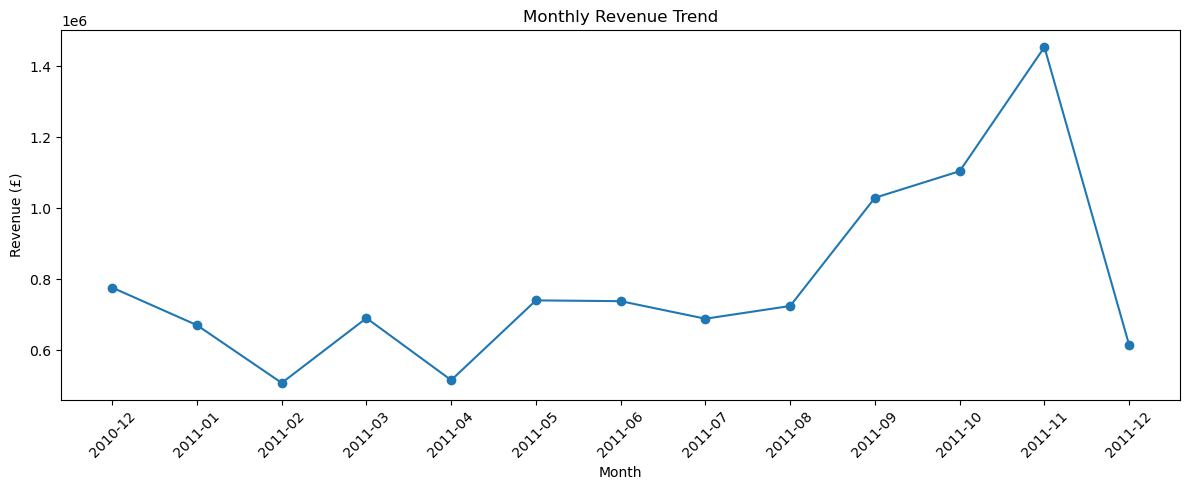

In [148]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [150]:
product_revenue = (
    df_product_sales
    .groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

product_revenue.head(10)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Revenue, dtype: float64

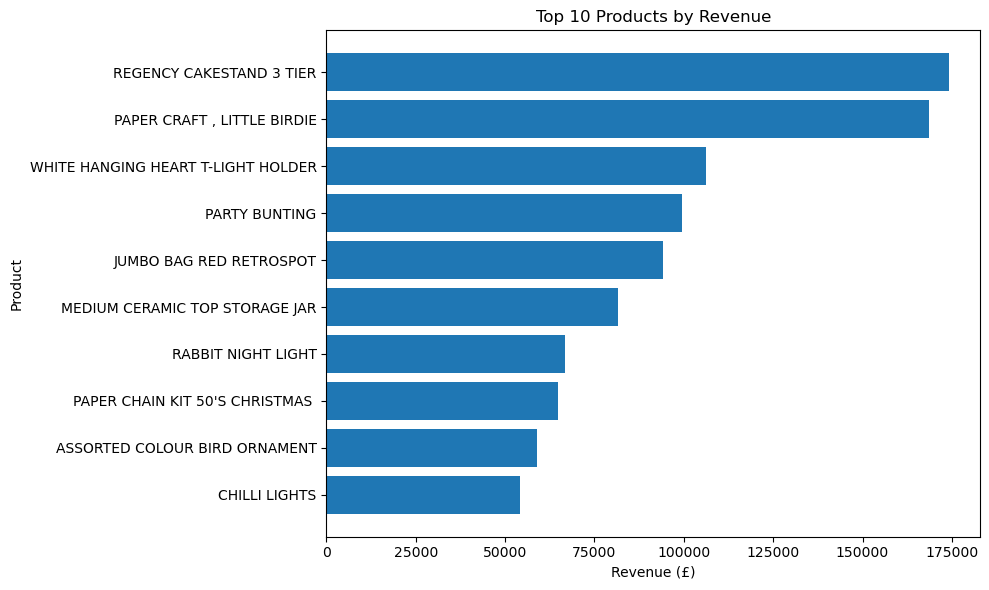

In [152]:
top_products = product_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_products.index,
    top_products.values
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [154]:
product_quantity = (
    df_product_sales
    .groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

product_quantity.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

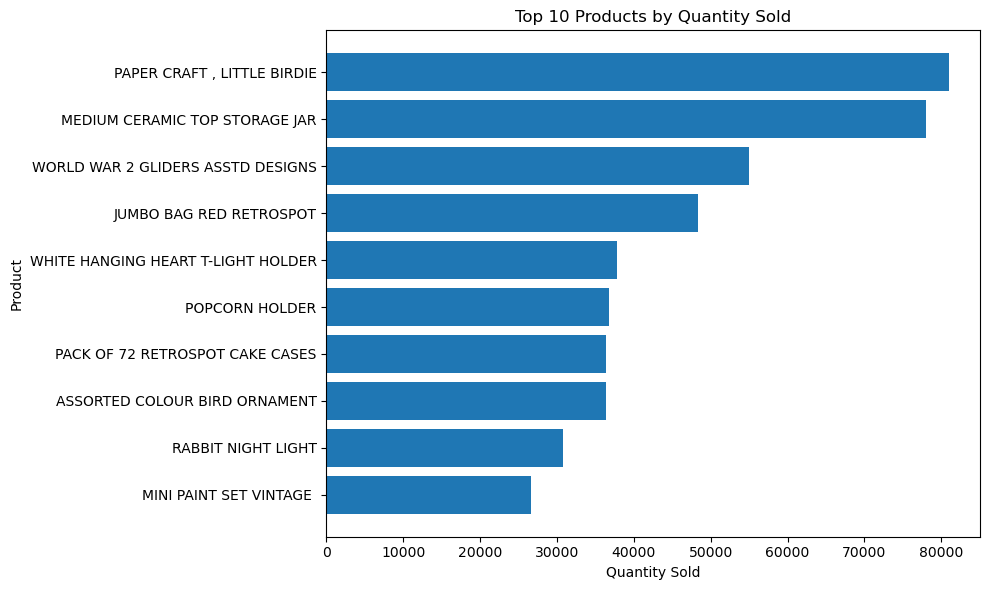

In [156]:
top_quantity = product_quantity.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_quantity.index,
    top_quantity.values
)

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Quantity Sold')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [158]:
country_revenue = (
    df_product_sales
    .groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

country_revenue.head(10)

Country
United Kingdom    8726832.534
Netherlands        283889.340
EIRE               276090.860
Germany            205381.150
France             184679.000
Australia          138103.810
Spain               55706.560
Switzerland         53065.600
Japan               37416.370
Belgium             36927.340
Name: Revenue, dtype: float64

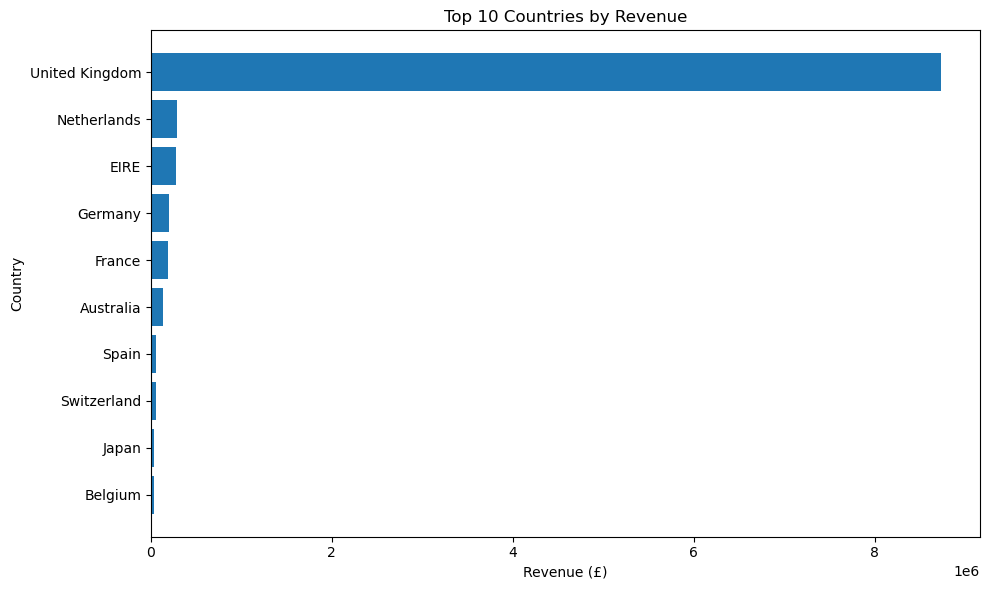

In [160]:
top_countries = country_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries.index,
    top_countries.values
)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

In [164]:
df_customer_sales = df_product_sales.dropna(subset=['CustomerID']).copy()

In [166]:
df_customer_sales.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Month'],
      dtype='object')

In [168]:
customer_revenue = (
    df_customer_sales
    .groupby('CustomerID')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

customer_revenue.head(10)

CustomerID
14646.0    279138.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    140336.83
12415.0    124564.53
14156.0    117210.08
17511.0     91062.38
12346.0     77183.60
16029.0     72708.09
Name: Revenue, dtype: float64

In [170]:
customer_orders = (
    df_customer_sales
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
)

customer_orders.head(10)

CustomerID
12748.0    206
14911.0    199
17841.0    124
13089.0     97
15311.0     91
14606.0     91
12971.0     86
14646.0     72
16029.0     62
13408.0     62
Name: InvoiceNo, dtype: int64

In [172]:
customer_aov = (
    customer_revenue / customer_orders
).sort_values(ascending=False)

customer_aov.head(10)

CustomerID
16446.0    84236.250000
12346.0    77183.600000
15749.0    14844.766667
15098.0    13305.500000
12590.0     9341.260000
12415.0     6228.226500
12357.0     6207.670000
12688.0     4873.810000
12752.0     4366.780000
18102.0     4327.621667
dtype: float64

In [174]:
customer_aov = (
    customer_revenue / customer_orders
).sort_values(ascending=False)

customer_aov.head(10)

CustomerID
16446.0    84236.250000
12346.0    77183.600000
15749.0    14844.766667
15098.0    13305.500000
12590.0     9341.260000
12415.0     6228.226500
12357.0     6207.670000
12688.0     4873.810000
12752.0     4366.780000
18102.0     4327.621667
dtype: float64

In [176]:
unique_customers = df_customer_sales['CustomerID'].nunique()

unique_customers

4335

In [178]:
df_product_sales['Quantity'].describe()

count    522726.000000
mean         10.639563
std         156.566366
min           1.000000
25%           1.000000
50%           4.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

In [182]:
Q1 = df_product_sales['Quantity'].quantile(0.25)
Q3 = df_product_sales['Quantity'].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

Q1, Q3, IQR, upper_limit

(1.0, 12.0, 11.0, 28.5)

In [184]:
quantity_outliers = df_product_sales[
    df_product_sales['Quantity'] > upper_limit
]

len(quantity_outliers)

26815

In [186]:
quantity_outliers[
    ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'CustomerID']
].sort_values('Quantity', ascending=False).head(10)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,12901.0
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,13135.0
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,18087.0
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,14609.0
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.0
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.0
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,16308.0
291249,562439,84879,ASSORTED COLOUR BIRD ORNAMENT,2880,1.45,12931.0


In [188]:
outlier_revenue = quantity_outliers['Revenue'].sum()

outlier_revenue

3854414.42

In [190]:
outlier_revenue_percentage = (
    outlier_revenue / total_revenue
) * 100

outlier_revenue_percentage

37.58503358734019

In [192]:
df_product_sales['UnitPrice'].describe()

count    522726.000000
mean          3.287968
std           4.465101
min           0.001000
25%           1.250000
50%           2.080000
75%           4.130000
max         649.500000
Name: UnitPrice, dtype: float64

In [194]:
price_Q1 = df_product_sales['UnitPrice'].quantile(0.25)
price_Q3 = df_product_sales['UnitPrice'].quantile(0.75)

price_IQR = price_Q3 - price_Q1

price_upper_limit = price_Q3 + 1.5 * price_IQR

price_Q1, price_Q3, price_IQR, price_upper_limit

(1.25, 4.13, 2.88, 8.45)

In [196]:
price_outliers = df_product_sales[
    df_product_sales['UnitPrice'] > price_upper_limit
]

len(price_outliers)

35926

In [198]:
price_outliers[
    ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'CustomerID']
].sort_values('UnitPrice', ascending=False).head(15)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5,15098.0
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5,15098.0
205759,554836,22655,VINTAGE RED KITCHEN CABINET,1,295.0,13015.0
118769,546480,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,13452.0
171178,551393,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,14973.0
32484,539080,22655,VINTAGE RED KITCHEN CABINET,1,295.0,16607.0
51636,540647,22655,VINTAGE RED KITCHEN CABINET,1,295.0,17406.0
4989,536835,22655,VINTAGE RED KITCHEN CABINET,1,295.0,13145.0
82768,543253,22655,VINTAGE RED KITCHEN CABINET,1,295.0,14842.0
133994,547814,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,13452.0


In [200]:
price_outlier_revenue = price_outliers['Revenue'].sum()

price_outlier_revenue

1232961.4

In [202]:
price_outlier_revenue_percentage = (
    price_outlier_revenue / total_revenue
) * 100

price_outlier_revenue_percentage

12.02281088157977

In [204]:
df_product_sales.shape

(522726, 10)

# Phase 3: Exploratory Data Analysis

Exploratory Data Analysis (EDA) was performed on the cleaned product sales dataset to understand overall sales performance, monthly trends, product performance, geographic contribution, customer behavior, and potential outliers.

The final product sales dataset contained **522,726 transaction-line records and 10 columns**, including the newly created `Revenue` and `Month` columns.

## 3.1 Revenue Calculation

A transaction-level `Revenue` column was created using:

**Revenue = Quantity × UnitPrice**

This column was used as the primary measure for sales and revenue analysis.

## 3.2 Overall Sales Metrics

The following key sales metrics were calculated:

- Total Revenue: **£10,255,184.18**
- Total Orders: **19,789**
- Average Order Value (AOV): **£518.23**

The total number of orders was calculated using unique `InvoiceNo` values because a single order can contain multiple transaction lines.

## 3.3 Monthly Revenue Analysis

Monthly revenue was calculated by grouping transaction-level revenue by the `Month` field.

The highest monthly revenue occurred in:

- **November 2011**
- Revenue: **£1,453,295.98**

Revenue increased noticeably from September through November 2011, followed by a decline in December 2011.

A monthly revenue trend visualization was created to communicate the changes over time.

The available data covers approximately one year, so the observed pattern was not treated as conclusive evidence of recurring seasonality.

## 3.4 Product Revenue Analysis

Products were analyzed based on total revenue generated.

The top revenue-generating products included:

- **REGENCY CAKESTAND 3 TIER** — £174,156.54
- **PAPER CRAFT, LITTLE BIRDIE** — £168,469.60
- **WHITE HANGING HEART T-LIGHT HOLDER** — £106,236.72
- **PARTY BUNTING** — £99,445.23
- **JUMBO BAG RED RETROSPOT** — £94,159.81

A horizontal bar chart was created to visualize the top 10 products by revenue.

## 3.5 Product Quantity Analysis

Products were also analyzed based on total quantity sold.

The highest-volume products included:

- **PAPER CRAFT, LITTLE BIRDIE** — 80,995 units
- **MEDIUM CERAMIC TOP STORAGE JAR** — 78,033 units
- **WORLD WAR 2 GLIDERS ASSTD DESIGNS** — 54,951 units
- **JUMBO BAG RED RETROSPOT** — 48,371 units
- **WHITE HANGING HEART T-LIGHT HOLDER** — 37,872 units

A horizontal bar chart was created to visualize the top 10 products by quantity sold.

The analysis demonstrated that the products with the highest revenue are not necessarily the same as the products with the highest sales volume.

## 3.6 Country Revenue Analysis

Revenue was analyzed by country to identify the major geographic markets in the dataset.

The top revenue-generating countries included:

- **United Kingdom** — £8,726,832.53
- **Netherlands** — £283,889.34
- **EIRE** — £276,090.86
- **Germany** — £205,381.15
- **France** — £184,679.00

The United Kingdom generated the largest share of revenue in this dataset.

A horizontal bar chart was created to visualize the top 10 countries by revenue.

## 3.7 Customer Analysis

Customer-level analysis was performed using records with available `CustomerID` values.

The final customer analysis dataset contained **4,335 unique customers**.

Customer revenue, order frequency, and average order value were analyzed.

The highest revenue-generating customer was:

- Customer **14646** — £279,138.02

The customer with the highest number of orders was:

- Customer **12748** — 206 orders

Customer average order value was also calculated to identify customers with high average spending per order.

The analysis showed that high purchase frequency does not necessarily correspond to the highest total revenue, highlighting the importance of using multiple customer metrics.

## 3.8 Outlier Analysis

Potential outliers were identified using the Interquartile Range (IQR) method.

### Quantity Outliers

For `Quantity`:

- Q1: **1**
- Q3: **12**
- IQR: **11**
- Upper outlier threshold: **28.5**
- Potential outlier transaction lines: **26,815**

These transactions generated:

- Revenue: **£3,854,414.42**
- Revenue share: **37.59%**

The extreme quantity records were investigated and included valid products, positive prices, and identifiable customers. Therefore, they were retained because they may represent legitimate bulk purchases.

### UnitPrice Outliers

For `UnitPrice`:

- Q1: **£1.25**
- Q3: **£4.13**
- IQR: **£2.88**
- Upper outlier threshold: **£8.45**
- Potential outlier transaction lines: **35,926**

These transactions generated:

- Revenue: **£1,232,961.40**
- Revenue share: **12.02%**

The highest-priced records were investigated and included legitimate higher-priced products such as furniture and premium items. Therefore, these records were also retained.

### Outlier Handling Approach

Outliers were not automatically removed based solely on statistical thresholds.

The approach followed was:

**Identify → Investigate → Validate → Retain or Remove**

This prevented legitimate high-volume or high-value transactions from being incorrectly excluded from the analysis.

## Key EDA Findings

The exploratory analysis revealed several important patterns:

1. Total product revenue was approximately **£10.26 million** across **19,789 orders**.
2. The average order value was approximately **£518.23**.
3. **November 2011** recorded the highest monthly revenue at approximately **£1.45 million**.
4. `PAPER CRAFT, LITTLE BIRDIE` had the highest quantity sold, while `REGENCY CAKESTAND 3 TIER` generated the highest product revenue.
5. The **United Kingdom** was the largest revenue-generating country in the dataset.
6. Customer revenue and order frequency showed different patterns, demonstrating the need for multiple customer-level metrics.
7. Statistically identified outliers represented substantial revenue and were therefore retained after validation rather than being removed automatically.

### Phase 3 Conclusion

EDA provided an initial understanding of the business's sales performance, product demand, geographic contribution, customer behavior, and unusual transaction patterns.

The findings from this phase will be used as a foundation for **statistical analysis and RFM customer segmentation in Phase 4**, followed by SQL analysis and Power BI dashboard development.

# Phase 4: Statistical Analysis & RFM Customer Segmentation

Statistical analysis was performed to understand customer purchasing behavior beyond basic sales metrics.

The analysis uses **RFM (Recency, Frequency, Monetary) analysis** to evaluate customers based on their purchasing activity and spending behavior.

## 4.1 RFM Analysis Overview

RFM analysis evaluates customers using three behavioral metrics:

| Metric | Definition | Business Question |
|---|---|---|
| **Recency** | Number of days since the customer's most recent purchase | How recently did the customer purchase? |
| **Frequency** | Number of unique orders placed by the customer | How often does the customer purchase? |
| **Monetary** | Total revenue generated by the customer | How much does the customer spend? |

RFM analysis helps identify differences in customer purchasing behavior and provides a foundation for customer segmentation.

## 4.2 Customer-Level Dataset

Customer-level analysis was performed using transactions with a valid `CustomerID`.

The final customer analysis dataset contains **4,335 unique customers**.

The analysis will calculate Recency, Frequency, and Monetary values for each customer before assigning RFM scores and customer segments.

## 4.3 RFM Segmentation

Customers will be assigned RFM scores based on their relative Recency, Frequency, and Monetary values.

These scores will be combined to create customer segments that can be analyzed based on purchasing behavior and revenue contribution.

## Phase 4 Objective

The objective of this phase is to:

1. Calculate customer Recency.
2. Calculate customer Frequency.
3. Calculate customer Monetary value.
4. Assign RFM scores.
5. Create meaningful customer segments.
6. Analyze the size and revenue contribution of each segment.
7. Identify customer behavior patterns that can support business decision-making.

In [211]:
df_customer_sales.shape

(391298, 10)

In [213]:
df_customer_sales['InvoiceDate'].max()

Timestamp('2011-12-09 12:50:00')

In [215]:
reference_date = df_customer_sales['InvoiceDate'].max() + pd.Timedelta(days=1)

reference_date

Timestamp('2011-12-10 12:50:00')

In [217]:
customer_last_purchase = (
    df_customer_sales
    .groupby('CustomerID')['InvoiceDate']
    .max()
)

customer_last_purchase.head()

CustomerID
12346.0   2011-01-18 10:01:00
12347.0   2011-12-07 15:52:00
12348.0   2011-09-25 13:13:00
12349.0   2011-11-21 09:51:00
12350.0   2011-02-02 16:01:00
Name: InvoiceDate, dtype: datetime64[ns]

In [219]:
customer_recency = (
    reference_date - customer_last_purchase
).dt.days

customer_recency.head()

CustomerID
12346.0    326
12347.0      2
12348.0     75
12349.0     19
12350.0    310
Name: InvoiceDate, dtype: int64

In [221]:
customer_frequency = (
    df_customer_sales
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
)

customer_frequency.head()


CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
Name: InvoiceNo, dtype: int64

In [223]:
customer_monetary = (
    df_customer_sales
    .groupby('CustomerID')['Revenue']
    .sum()
)

customer_monetary.head()

CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1437.24
12349.0     1457.55
12350.0      294.40
Name: Revenue, dtype: float64

In [225]:
rfm = pd.concat(
    [customer_recency, customer_frequency, customer_monetary],
    axis=1
)

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1437.24
12349.0,19,1,1457.55
12350.0,310,1,294.40


In [227]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'],
    5,
    labels=[5, 4, 3, 2, 1],
    duplicates='drop'
)

rfm[['Recency', 'R_Score']].head()

,Recency,R_Score
CustomerID,,
12346.0,326,1
12347.0,2,5
12348.0,75,2
12349.0,19,4
12350.0,310,1


In [229]:
rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm[['Frequency', 'F_Score']].head()

,Frequency,F_Score
CustomerID,,
12346.0,1,1
12347.0,7,5
12348.0,4,4
12349.0,1,1
12350.0,1,1


In [231]:
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm[['Monetary', 'M_Score']].head()

,Monetary,M_Score
CustomerID,,
12346.0,77183.60,5
12347.0,4310.00,5
12348.0,1437.24,4
12349.0,1457.55,4
12350.0,294.40,2


In [233]:
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(int)
    + rfm['F_Score'].astype(int)
    + rfm['M_Score'].astype(int)
)

rfm[['Recency', 'Frequency', 'Monetary',
     'R_Score', 'F_Score', 'M_Score', 'RFM_Score']].head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,5,7
12347.0,2,7,4310.00,5,5,5,15
12348.0,75,4,1437.24,2,4,4,10
12349.0,19,1,1457.55,4,1,4,9
12350.0,310,1,294.40,1,1,2,4


In [235]:
def rfm_segment(score):
    if score >= 13:
        return 'Champions'
    elif score >= 10:
        return 'Loyal Customers'
    elif score >= 7:
        return 'Potential Loyalists'
    elif score >= 5:
        return 'At Risk'
    else:
        return 'Hibernating'

rfm['Segment'] = rfm['RFM_Score'].apply(rfm_segment)

rfm[['RFM_Score', 'Segment']].head()

,RFM_Score,Segment
CustomerID,,
12346.0,7,Potential Loyalists
12347.0,15,Champions
12348.0,10,Loyal Customers
12349.0,9,Potential Loyalists
12350.0,4,Hibernating


In [237]:
segment_counts = (
    rfm['Segment']
    .value_counts()
)

segment_counts

Segment
Potential Loyalists    1073
Loyal Customers        1021
Champions               927
At Risk                 774
Hibernating             540
Name: count, dtype: int64

In [239]:
segment_percentage = (
    segment_counts / len(rfm) * 100
).round(2)

segment_percentage

Segment
Potential Loyalists    24.75
Loyal Customers        23.55
Champions              21.38
At Risk                17.85
Hibernating            12.46
Name: count, dtype: float64

In [241]:
segment_revenue = (
    rfm.groupby('Segment')['Monetary']
    .sum()
    .sort_values(ascending=False)
)

segment_revenue

Segment
Champions              6124384.940
Loyal Customers        1436807.871
Potential Loyalists     818978.122
At Risk                 262290.481
Hibernating             101617.230
Name: Monetary, dtype: float64

In [243]:
segment_revenue_percentage = (
    segment_revenue / segment_revenue.sum() * 100
).round(2)

segment_revenue_percentage

Segment
Champions              70.04
Loyal Customers        16.43
Potential Loyalists     9.37
At Risk                 3.00
Hibernating             1.16
Name: Monetary, dtype: float64

In [245]:
rfm_summary = pd.DataFrame({
    'Customers': segment_counts,
    'Customer_Percentage': segment_percentage,
    'Revenue': segment_revenue,
    'Revenue_Percentage': segment_revenue_percentage
})

rfm_summary

,Customers,Customer_Percentage,Revenue,Revenue_Percentage
Segment,,,,
At Risk,774,17.85,262290.481,3.00
Champions,927,21.38,6124384.940,70.04
Hibernating,540,12.46,101617.230,1.16
Loyal Customers,1021,23.55,1436807.871,16.43
Potential Loyalists,1073,24.75,818978.122,9.37


In [247]:
segment_avg_revenue = (
    rfm.groupby('Segment')['Monetary']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

segment_avg_revenue

Segment
Champions              6606.67
Loyal Customers        1407.26
Potential Loyalists     763.26
At Risk                 338.88
Hibernating             188.18
Name: Monetary, dtype: float64

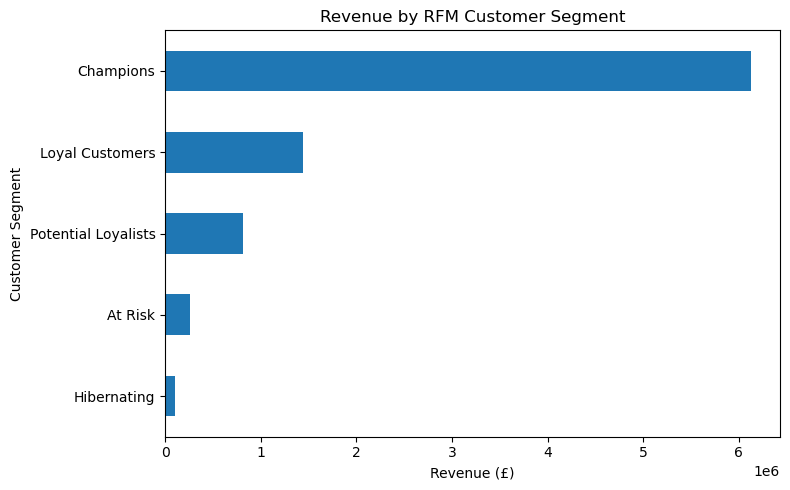

In [249]:
import matplotlib.pyplot as plt

segment_revenue.sort_values().plot(
    kind='barh',
    figsize=(8, 5)
)

plt.title('Revenue by RFM Customer Segment')
plt.xlabel('Revenue (£)')
plt.ylabel('Customer Segment')
plt.tight_layout()
plt.show()

# Phase 4: Statistical Analysis & RFM Customer Segmentation

Statistical analysis was performed to understand customer purchasing behavior beyond basic sales metrics.

RFM (Recency, Frequency, Monetary) analysis was used to evaluate customers based on their purchasing activity and spending behavior.

## 4.1 RFM Analysis

RFM analysis evaluates customers using three behavioral metrics:

| Metric | Definition | Business Question |
|---|---|---|
| **Recency** | Number of days since the customer's most recent purchase | How recently did the customer purchase? |
| **Frequency** | Number of unique orders placed by the customer | How often does the customer purchase? |
| **Monetary** | Total revenue generated by the customer | How much does the customer spend? |

A reference date of **2011-12-10** was used for calculating customer recency.

## 4.2 Customer-Level Analysis

RFM analysis was performed only for transactions with a valid `CustomerID`.

The final customer analysis dataset contained **4,335 unique customers**.

The RFM metrics were calculated at customer level:

- Recency was calculated from the customer's latest purchase date.
- Frequency was calculated using the number of unique invoices/orders.
- Monetary value was calculated as the total revenue generated by the customer.

## 4.3 RFM Scoring

Customers were divided into five groups for each RFM metric.

The scoring approach was:

- **Recency:** Lower recency received a higher score.
- **Frequency:** Higher frequency received a higher score.
- **Monetary:** Higher monetary value received a higher score.

Each customer therefore received an R, F, and M score from **1 to 5**.

The combined RFM score was calculated as:

**RFM Score = R Score + F Score + M Score**

The resulting score ranged from **3 to 15**.

## 4.4 Customer Segmentation

Customers were grouped into five segments based on their combined RFM score:

| RFM Score | Segment |
|---:|---|
| 13–15 | Champions |
| 10–12 | Loyal Customers |
| 7–9 | Potential Loyalists |
| 5–6 | At Risk |
| 3–4 | Hibernating |

These segment thresholds were defined specifically for this project to provide a simple and interpretable customer segmentation framework.

## 4.5 RFM Segment Summary

| Segment | Customers | Customer % | Revenue | Revenue % |
|---|---:|---:|---:|---:|
| Champions | 927 | 21.38% | £6,124,384.94 | 70.04% |
| Loyal Customers | 1,021 | 23.55% | £1,436,807.87 | 16.43% |
| Potential Loyalists | 1,073 | 24.75% | £818,978.12 | 9.37% |
| At Risk | 774 | 17.85% | £262,290.48 | 3.00% |
| Hibernating | 540 | 12.46% | £101,617.23 | 1.16% |

The revenue percentages are calculated within the **4,335 customers with valid CustomerIDs**.

## 4.6 Average Revenue per Customer

Average revenue per customer was also calculated for each segment:

| Segment | Average Revenue per Customer |
|---|---:|
| Champions | £6,606.67 |
| Loyal Customers | £1,407.26 |
| Potential Loyalists | £763.26 |
| At Risk | £338.88 |
| Hibernating | £188.18 |

## 4.7 Key Findings

The RFM analysis identified significant differences in customer purchasing behavior.

- Champions represented **21.38% of identified customers** and contributed **70.04% of identified-customer revenue**.
- Loyal Customers represented **23.55% of customers** and contributed **16.43% of revenue**.
- Potential Loyalists represented the largest customer segment at **24.75%**.
- At Risk customers accounted for **17.85% of customers** but contributed **3.00% of revenue**.
- Hibernating customers accounted for **12.46% of customers** and contributed **1.16% of revenue**.
- Average revenue per customer was highest for Champions at **£6,606.67**.

These findings demonstrate how RFM analysis can be used to understand customer value and purchasing behavior at the individual customer level.

## Phase 4 Conclusion

RFM analysis successfully transformed transaction-level data into customer-level behavioral segments.

The analysis identified **4,335 customers** across five RFM segments and quantified both customer distribution and revenue contribution.

The resulting customer segments will be used in later stages of the project for **SQL analysis, Power BI visualization, and business insight generation**.

In [252]:
df_product_sales.to_csv(
    'ecommerce_sales_cleaned.csv',
    index=False
)

# Phase 5: SQL Business Analysis

SQL analysis was performed using **MySQL Workbench** to analyze the cleaned e-commerce transaction dataset and answer key business questions.

## 5.1 SQL Database Setup

The cleaned dataset was imported into a MySQL database:

- **Database:** `ecommerce_analytics`
- **Table:** `ecommerce_sales_cleaned`
- **Rows:** 522,726
- **Columns:** 10

The table contains transaction-level sales data including invoice information, products, quantities, prices, customer IDs, countries, revenue, and month.

## 5.2 Product Analysis

SQL aggregation was used to identify products with the highest sales quantities and revenue.

The top products by quantity included:

- PAPER CRAFT, LITTLE BIRDIE
- MEDIUM CERAMIC TOP STORAGE JAR
- WORLD WAR 2 GLIDERS ASSTD DESIGNS
- JUMBO BAG RED RETROSPOT
- WHITE HANGING HEART T-LIGHT HOLDER

Revenue-based product analysis also identified the highest-revenue products.

## 5.3 Monthly Revenue Analysis

Monthly revenue was calculated using `SUM(Revenue)` and grouped by `Month`.

The highest monthly revenue occurred in:

**November 2011 — £1,453,295.98**

The dataset covers approximately 13 months, so the analysis describes the observed period rather than establishing a long-term seasonal pattern.

## 5.4 Monthly Order Analysis

The number of unique orders was calculated using:

`COUNT(DISTINCT InvoiceNo)`

Orders were grouped by month to understand changes in purchasing activity over time.

## 5.5 Monthly Average Order Value

Monthly AOV was calculated using:

**Monthly AOV = Total Revenue / Number of Unique Orders**

This metric was used to compare the average order value across different months.

## 5.6 Customer Revenue Analysis

Customer-level revenue was calculated by grouping transactions by `CustomerID`.

Customers with missing or blank CustomerIDs were excluded from customer-level analysis.

The highest-revenue identified customers included:

| CustomerID | Revenue |
|---:|---:|
| 14646 | £279,138.02 |
| 18102 | £259,657.30 |
| 17450 | £194,390.79 |
| 16446 | £168,472.50 |
| 14911 | £140,336.83 |

## 5.7 Country Revenue Analysis

Revenue was grouped by country to understand the geographic distribution of sales.

The United Kingdom generated the highest observed revenue at approximately:

**£8.73 million**

Other high-revenue countries included the Netherlands, EIRE, Germany, and France.

## 5.8 Repeat Customer Analysis

Customers were classified as repeat customers when they had placed more than one unique order.

The analysis showed that:

**65.29% of identified customers were repeat customers.**

This metric was calculated only for customers with valid CustomerIDs.

## 5.9 Average Orders per Customer

The average number of unique orders per identified customer was:

**4.56 orders per customer**

This provides an overall measure of purchasing frequency during the dataset period.

## 5.10 Customer Average Order Value

Customer-level AOV was calculated as:

**Customer AOV = Total Customer Revenue / Number of Unique Customer Orders**

This helped identify customers with particularly high average transaction values.

## 5.11 Customer Revenue Ranking

SQL window functions were used to rank customers based on total revenue.

The `RANK()` function was used to assign revenue rankings.

The highest-ranked identified customers were:

| Rank | CustomerID | Revenue |
|---:|---:|---:|
| 1 | 14646 | £279,138.02 |
| 2 | 18102 | £259,657.30 |
| 3 | 17450 | £194,390.79 |
| 4 | 16446 | £168,472.50 |
| 5 | 14911 | £140,336.83 |

Blank CustomerIDs were excluded using both `IS NOT NULL` and a blank-string check.

## 5.12 SQL Concepts Used

The SQL analysis used the following concepts:

- `SELECT`
- `WHERE`
- `GROUP BY`
- `ORDER BY`
- `SUM()`
- `COUNT()`
- `COUNT(DISTINCT ...)`
- `AVG()`
- `ROUND()`
- Subqueries
- Conditional logic using `CASE`
- Window functions using `RANK()`

## Phase 5 Conclusion

SQL analysis transformed the cleaned transaction dataset into business-oriented metrics covering **products, revenue, orders, customers, countries, purchasing frequency, and customer rankings**.

The analysis also demonstrated practical SQL skills including aggregation, filtering, subqueries, conditional logic, and window functions.

The SQL results will be used alongside the Python analysis in the later **Excel and Power BI stages** of the project.

In [1]:
# Phase 7.1: Monthly Sales Growth Analysis

sales_df = df.copy()

# Convert InvoiceDate to datetime
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

# Calculate revenue
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

# Extract month
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = (
    sales_df.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

# Calculate previous month's revenue
monthly_sales["Previous_Month_Revenue"] = monthly_sales["Revenue"].shift(1)

# Calculate month-over-month growth percentage
monthly_sales["MoM_Growth_%"] = (
    monthly_sales["Revenue"].pct_change() * 100
).round(2)

# Display results
monthly_sales

NameError: name 'df' is not defined

In [3]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

ImportError: Missing optional dependency 'openpyxl'.  Use pip or conda to install openpyxl.

In [4]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# Phase 7.1: Monthly Sales Growth Analysis

# Create a copy of the dataset
sales_df = df.copy()

# Convert InvoiceDate to datetime
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

# Calculate revenue
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

# Extract month
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = (
    sales_df.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

# Calculate previous month's revenue
monthly_sales["Previous_Month_Revenue"] = (
    monthly_sales["Revenue"].shift(1)
)

# Calculate monthly growth percentage
monthly_sales["MoM_Growth_%"] = (
    monthly_sales["Revenue"].pct_change() * 100
).round(2)

# Display results
monthly_sales

,Month,Revenue,Previous_Month_Revenue,MoM_Growth_%
0,2010-12,748957.020,NaN,NaN
1,2011-01,560000.260,748957.020,-25.23
2,2011-02,498062.650,560000.260,-11.06
3,2011-03,683267.080,498062.650,37.18
4,2011-04,493207.121,683267.080,-27.82
5,2011-05,723333.510,493207.121,46.66
6,2011-06,691123.120,723333.510,-4.45
7,2011-07,681300.111,691123.120,-1.42
8,2011-08,682680.510,681300.111,0.20
9,2011-09,1019687.622,682680.510,49.37


In [7]:
# Phase 7.1: Key Business Insights

# Month with the highest revenue
highest_month = monthly_sales.loc[monthly_sales["Revenue"].idxmax()]

# Month with the lowest revenue
lowest_month = monthly_sales.loc[monthly_sales["Revenue"].idxmin()]

# Month with the highest growth
strongest_growth = monthly_sales.loc[
    monthly_sales["MoM_Growth_%"].idxmax()
]

# Month with the lowest growth
weakest_growth = monthly_sales.loc[
    monthly_sales["MoM_Growth_%"].idxmin()
]

print("HIGHEST REVENUE MONTH")
print(highest_month)

print("\nLOWEST REVENUE MONTH")
print(lowest_month)

print("\nSTRONGEST MONTH-OVER-MONTH GROWTH")
print(strongest_growth)

print("\nWEAKEST MONTH-OVER-MONTH GROWTH")
print(weakest_growth)

HIGHEST REVENUE MONTH
Month                        2011-11
Revenue                   1461756.25
Previous_Month_Revenue    1070704.67
MoM_Growth_%                   36.52
Name: 11, dtype: object

LOWEST REVENUE MONTH
Month                        2011-12
Revenue                    433668.01
Previous_Month_Revenue    1461756.25
MoM_Growth_%                  -70.33
Name: 12, dtype: object

STRONGEST MONTH-OVER-MONTH GROWTH
Month                         2011-09
Revenue                   1019687.622
Previous_Month_Revenue      682680.51
MoM_Growth_%                    49.37
Name: 9, dtype: object

WEAKEST MONTH-OVER-MONTH GROWTH
Month                        2011-12
Revenue                    433668.01
Previous_Month_Revenue    1461756.25
MoM_Growth_%                  -70.33
Name: 12, dtype: object


## Phase 7.1: Monthly Sales Growth — Business Insights

### Key Findings
- November 2011 recorded the highest monthly revenue of 1,461,756.25.
- December 2011 recorded the lowest monthly revenue of 433,668.01.
- September 2011 showed the strongest month-over-month revenue growth at 49.37%.
- December 2011 experienced the largest month-over-month decline at 70.33%.

### Business Interpretation
The results show that monthly revenue fluctuated considerably during the analysis period. November recorded the highest revenue, while December experienced a substantial decline compared with November.

These patterns may reflect seasonal purchasing behaviour, changes in customer demand, or differences in the number and value of transactions. Further investigation is needed before identifying the exact cause.

### Business Recommendations
- Investigate the products and customer segments contributing to November's high revenue.
- Compare November and December sales to understand which products or customer groups contributed most to the decline.
- Review monthly sales trends to support inventory planning and promotional decisions.
- Monitor month-over-month revenue growth to identify significant changes in business performance.

### Conclusion
Monthly sales growth analysis helps identify revenue peaks, declines, and changing sales patterns. These findings can support better sales planning, inventory management, and targeted marketing decisions.

In [8]:
# Phase 7.2: Customer Retention Analysis

# Create a copy of the dataset
retention_df = df.copy()

# Convert InvoiceDate to datetime
retention_df["InvoiceDate"] = pd.to_datetime(
    retention_df["InvoiceDate"]
)

# Calculate revenue
retention_df["Revenue"] = (
    retention_df["Quantity"] * retention_df["UnitPrice"]
)

# Remove rows without CustomerID
retention_df = retention_df.dropna(subset=["CustomerID"])

# Count distinct invoices for each customer
customer_orders = (
    retention_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index(name="Total_Orders")
)

# Classify customers
customer_orders["Customer_Type"] = customer_orders[
    "Total_Orders"
].apply(
    lambda x: "Repeat Customer" if x > 1 else "One-Time Customer"
)

# Calculate customer counts
customer_summary = customer_orders["Customer_Type"].value_counts()

total_customers = len(customer_orders)
one_time_customers = customer_summary.get("One-Time Customer", 0)
repeat_customers = customer_summary.get("Repeat Customer", 0)

repeat_customer_rate = (
    repeat_customers / total_customers * 100
    if total_customers > 0 else 0
)

# Display results
print("CUSTOMER RETENTION ANALYSIS")
print("-" * 40)
print("Total Unique Customers:", total_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)
print("Repeat Customer Rate:", round(repeat_customer_rate, 2), "%")

# Display customer type distribution
customer_summary

CUSTOMER RETENTION ANALYSIS
----------------------------------------
Total Unique Customers: 4372
One-Time Customers: 1313
Repeat Customers: 3059
Repeat Customer Rate: 69.97 %


Customer_Type
Repeat Customer      3059
One-Time Customer    1313
Name: count, dtype: int64

In [9]:
# Phase 7.2: Revenue by Customer Type

# Merge customer classifications with transaction data
customer_revenue = retention_df.merge(
    customer_orders[["CustomerID", "Customer_Type"]],
    on="CustomerID",
    how="left"
)

# Calculate revenue by customer type
revenue_by_customer_type = (
    customer_revenue.groupby("Customer_Type")["Revenue"]
    .sum()
    .reset_index()
)

# Calculate total revenue
total_revenue = revenue_by_customer_type["Revenue"].sum()

# Calculate revenue contribution percentage
revenue_by_customer_type["Revenue_Percentage"] = (
    revenue_by_customer_type["Revenue"] / total_revenue * 100
).round(2)

# Display results
print("REVENUE BY CUSTOMER TYPE")
display(revenue_by_customer_type)

print("\nTOTAL REVENUE:", round(total_revenue, 2))

REVENUE BY CUSTOMER TYPE


,Customer_Type,Revenue,Revenue_Percentage
0,One-Time Customer,433784.671,5.23
1,Repeat Customer,7866281.143,94.77



TOTAL REVENUE: 8300065.81


## Phase 7.2: Customer Retention Analysis — Business Insights

### Key Findings
- The analysis identified 4,372 unique customers with available CustomerIDs.
- A total of 3,059 customers were classified as repeat customers, while 1,313 were classified as one-time customers.
- Repeat customers accounted for 69.97% of identified customers.
- Repeat customers contributed 94.77% of the calculated revenue.
- One-time customers contributed 5.23% of the calculated revenue.

### Business Interpretation
The results indicate that repeat customers are an important source of revenue in the dataset. Although one-time customers represent approximately 30% of identified customers, their calculated revenue contribution is relatively small.

### Business Recommendations
- Develop targeted campaigns to encourage one-time customers to make another purchase.
- Analyze repeat customers' purchase frequency and spending patterns to understand valuable customer behaviours.
- Consider loyalty rewards and personalized promotions to strengthen customer relationships.
- Monitor repeat purchase rates and customer revenue contributions over time.

### Conclusion
Customer retention analysis helps distinguish one-time and repeat purchasers and measure their revenue contributions. These findings can support customer retention strategies and more informed marketing decisions.

In [11]:
# Phase 7.3: Advanced RFM Customer Segmentation

import pandas as pd

# Create a copy of the transaction data
rfm_df = retention_df.copy()

# Remove rows without CustomerID
rfm_df = rfm_df.dropna(subset=["CustomerID"])

# Calculate revenue
rfm_df["Revenue"] = rfm_df["Quantity"] * rfm_df["UnitPrice"]

# Set the analysis date to one day after the latest invoice date
analysis_date = rfm_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = rfm_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (analysis_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

# Round monetary values
rfm["Monetary"] = rfm["Monetary"].round(2)

# Display the first five customers
print("RFM ANALYSIS — FIRST FIVE CUSTOMERS")
display(rfm.head())

# Display summary statistics
print("\nRFM SUMMARY")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

RFM ANALYSIS — FIRST FIVE CUSTOMERS


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,2,0.00
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40



RFM SUMMARY


,Recency,Frequency,Monetary
count,4372.00,4372.00,4372.00
mean,92.05,5.08,1898.46
std,100.77,9.34,8219.35
min,1.00,1.00,-4287.63
25%,17.00,1.00,293.36
50%,50.00,3.00,648.08
75%,143.00,5.00,1611.72
max,374.00,248.00,279489.02


In [12]:
# Phase 7.3: RFM Scoring

# Assign scores from 1 to 5
# Lower recency is better, so reverse the score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Higher frequency and monetary values receive higher scores
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

# Display the results
print("RFM SCORING RESULTS")
display(rfm.head(10))

print("\nRFM SCORE DISTRIBUTION")
display(rfm[["R_Score", "F_Score", "M_Score"]].describe())

RFM SCORING RESULTS


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,2,0.00,1,2,1,121
1,12347.0,2,7,4310.00,5,4,5,545
2,12348.0,75,4,1797.24,2,3,4,234
3,12349.0,19,1,1757.55,4,1,4,414
4,12350.0,310,1,334.40,1,1,2,112
5,12352.0,36,11,1545.41,3,5,4,354
6,12353.0,204,1,89.00,1,1,1,111
7,12354.0,232,1,1079.40,1,1,4,114
8,12355.0,214,1,459.40,1,1,2,112
9,12356.0,23,3,2811.43,4,3,5,435



RFM SCORE DISTRIBUTION


,R_Score,F_Score,M_Score
count,4372.000000,4372.000000,4372.000000
mean,3.000000,3.000000,3.000000
std,1.414699,1.414699,1.414699
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,2.000000
50%,3.000000,3.000000,3.000000
75%,4.000000,4.000000,4.000000
max,5.000000,5.000000,5.000000


In [13]:
# Phase 7.3: Customer Segmentation

def segment_customer(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    elif r >= 4 and f >= 2:
        return "Potential Loyalists"

    elif r <= 2 and f >= 3:
        return "At-Risk Customers"

    elif r <= 2 and f <= 2:
        return "Lost Customers"

    else:
        return "Needs Attention"


# Assign segments
rfm["Customer_Segment"] = rfm.apply(segment_customer, axis=1)

# Summarize customer counts
segment_summary = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Total_Revenue=("Monetary", "sum"),
        Average_Revenue=("Monetary", "mean")
    )
    .reset_index()
)

# Calculate percentage of customers
segment_summary["Customer_Percentage"] = (
    segment_summary["Customer_Count"] / len(rfm) * 100
).round(2)

# Calculate revenue contribution
total_rfm_revenue = rfm["Monetary"].sum()

segment_summary["Revenue_Percentage"] = (
    segment_summary["Total_Revenue"] / total_rfm_revenue * 100
).round(2)

# Round financial values
segment_summary["Total_Revenue"] = segment_summary["Total_Revenue"].round(2)
segment_summary["Average_Revenue"] = segment_summary["Average_Revenue"].round(2)

# Display results
print("CUSTOMER SEGMENTATION SUMMARY")
display(segment_summary.sort_values("Total_Revenue", ascending=False))

CUSTOMER SEGMENTATION SUMMARY


,Customer_Segment,Customer_Count,Total_Revenue,Average_Revenue,Customer_Percentage,Revenue_Percentage
1,Champions,964,5620812.18,5830.72,22.05,67.72
3,Loyal Customers,484,841162.11,1737.94,11.07,10.13
0,At-Risk Customers,689,756019.58,1097.27,15.76,9.11
2,Lost Customers,1060,398791.57,376.22,24.25,4.80
4,Needs Attention,694,357230.66,514.74,15.87,4.30
5,Potential Loyalists,481,326049.71,677.86,11.00,3.93


## Phase 7.3: RFM Customer Segmentation — Business Insights

### Key Findings
- The analysis classified 4,372 customers into six RFM-based segments.
- Champions represented 22.05% of customers and contributed 67.72% of calculated revenue.
- Lost Customers formed the largest segment, representing 24.25% of customers.
- Loyal Customers contributed 10.13% of calculated revenue.
- At-Risk Customers represented 15.76% of customers and contributed 9.11% of calculated revenue.

### Business Recommendations
- **Champions:** Prioritize retention through loyalty rewards, personalized recommendations, and exclusive offers.
- **Loyal Customers:** Encourage continued purchasing through relevant promotions and loyalty programs.
- **At-Risk Customers:** Investigate declining purchasing activity and test targeted re-engagement campaigns.
- **Lost Customers:** Evaluate win-back campaigns and identify reasons for customer inactivity.
- **Potential Loyalists:** Encourage repeat purchases through personalized product recommendations.
- **Needs Attention:** Review purchasing patterns to determine appropriate engagement strategies.

### Conclusion
RFM analysis provides a structured way to understand customer purchasing behaviour and distinguish high-value, loyal, and potentially inactive customers. These segments can support more targeted marketing, customer retention, and revenue management strategies.

The findings should be validated after reviewing cancelled invoices and returned transactions.

## Phase 7.4: Business Insights and Recommendations

### Key Business Insights

**1. Monthly Sales Performance**
- Monthly revenue analysis identifies periods of strong and weak sales performance.
- The highest-revenue month was November 2011, with revenue of approximately 1.46 million in the dataset's currency units.
- December 2011 recorded the sharpest month-over-month decline, highlighting the need to investigate seasonal patterns and changes in customer demand.

**2. Customer Retention**
- The analysis identified 4,372 unique customers.
- Repeat customers accounted for approximately 69.97% of customers.
- Repeat customers generated approximately 94.77% of total revenue, demonstrating the importance of customer retention.

**3. Customer Segmentation**
- Champions generated approximately 67.72% of customer revenue in the segmentation results.
- Loyal Customers contributed approximately 10.13% of customer revenue.
- At-Risk Customers and Lost Customers represent opportunities for targeted re-engagement campaigns.

### Business Recommendations

1. **Improve Customer Retention:** Introduce loyalty rewards, personalized offers, and exclusive promotions to encourage repeat purchases.
2. **Re-engage At-Risk Customers:** Use targeted email campaigns, discounts, and product recommendations to encourage customers to return.
3. **Investigate Lost Customers:** Analyze purchasing history and inactivity patterns to identify possible reasons for customer loss.
4. **Reward High-Value Customers:** Offer special benefits to Champions and Loyal Customers to strengthen long-term relationships.
5. **Plan for Seasonal Demand:** Use monthly sales trends to improve inventory planning, marketing campaigns, and promotional timing.
6. **Monitor Business KPIs:** Regularly track revenue, monthly growth, repeat-purchase rate, average order value, and customer-segment revenue.

### Conclusion

The advanced business analysis combines sales growth, customer retention, and RFM-based customer segmentation to identify important business trends and opportunities. The findings can help businesses improve customer loyalty, prioritize high-value customers, re-engage inactive customers, and make more informed sales and marketing decisions.

# Phase 8: Business Recommendations & Final Documentation

## 8.1 Project Objective

The objective of this phase is to convert the results from Python, SQL, customer retention analysis, RFM segmentation, and Excel dashboards into actionable business recommendations.

## 8.2 Key Business Findings

- **Sales Performance:** Monthly revenue analysis identified November 2011 as the highest-revenue month, while December 2011 recorded the lowest revenue in the available analysis.
- **Sales Growth:** September 2011 recorded the strongest month-over-month revenue growth at 49.37%, while December 2011 showed the largest decline at -70.33%.
- **Customer Retention:** The analysis identified 4,372 unique customers. Of these, 3,059 were repeat customers, giving a repeat-customer rate of approximately 69.97%.
- **Revenue Contribution:** Repeat customers generated approximately 94.77% of total revenue, highlighting their importance to business performance.
- **Customer Segmentation:** Champions generated approximately 67.72% of revenue, making them the largest revenue-contributing customer segment in the current analysis.

## 8.3 Business Recommendations

1. **Improve Customer Retention:** Introduce loyalty rewards, personalized offers, and targeted email campaigns to encourage repeat purchases.
2. **Retain High-Value Customers:** Provide exclusive offers and early access to products for Champions and Loyal Customers.
3. **Re-engage At-Risk Customers:** Use targeted promotions and personalized communication to encourage customers who have not purchased recently to return.
4. **Investigate Sales Declines:** Examine December 2011 sales by product, customer, and transaction to understand the reasons for the decline before making operational decisions.
5. **Increase Customer Value:** Recommend related products and bundle complementary items to encourage larger purchases.
6. **Monitor Business KPIs:** Track monthly revenue, month-over-month growth, repeat-customer rate, average order value, and revenue by customer segment regularly.

## 8.4 Final Conclusion

This project combines Python-based data cleaning and exploratory data analysis, SQL-based business analysis, customer retention analysis, RFM customer segmentation, and Excel dashboard reporting. The results provide insights into sales trends, customer purchasing behavior, and revenue contribution across customer segments. These findings can help businesses monitor performance, improve customer retention, and develop data-driven marketing strategies.

## Phase 8 Conclusion

The business findings and recommendations have been documented based on sales performance, customer retention, and RFM customer segmentation. These insights provide a foundation for the final dashboard and project presentation.

**Phase 8 Status: Completed**